# Credit Risk Modeling with SMOTE and SHAP (German Credit Data)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sayleeraut/credit-risk-modeling/blob/main/credit_risk_modeling.ipynb)

## 1. Project goal

When a bank approves a loan for someone who later **defaults**, it loses far more money than it gains from a good customer. The goal of this project is to build a model that **identifies risky loan applicants** before the loan is granted.

In this notebook I:

1. explore the applicants and show the **class imbalance** (far fewer bad loans than good ones),
2. fix the imbalance with **SMOTE**, applied **only to the training data**,
3. train and tune **Logistic Regression, a Decision Tree, and two ensembles (Random Forest and XGBoost)**,
4. evaluate them with a focus on **recall** (catching defaulters) and **ROC-AUC**, plus the dataset's official **misclassification cost**,
5. explain the model with **SHAP**: a summary plot, global feature importance, and a breakdown of **one individual applicant's** decision.

## 2. Dataset description and source

**Statlog (German Credit Data)**, collected by Prof. Hans Hofmann (University of Hamburg) and published in the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data). It contains **1,000 real loan applicants** from a German bank, each labelled as a **good** or **bad** credit risk.

I load it through [OpenML (dataset 31, `credit-g`)](https://www.openml.org/d/31), which hosts the same UCI data with readable category labels instead of codes like `A11`.

| Type | Features |
|---|---|
| Loan | `duration` (months), `credit_amount` (DM), `purpose`, `installment_commitment` (instalment as % of income) |
| Financial situation | `checking_status`, `savings_status`, `credit_history`, `existing_credits`, `other_payment_plans`, `other_parties` (co-applicant or guarantor) |
| Personal / stability | `age`, `employment` (years), `job`, `housing`, `property_magnitude`, `residence_since`, `num_dependents`, `own_telephone`, `personal_status`, `foreign_worker` |
| **Target** | `class`: *good* or *bad* |

The dataset documentation includes a **cost matrix**: classifying a *bad* applicant as *good* costs **5**, while rejecting a *good* applicant costs **1**. Missing a defaulter is five times worse than a false alarm, so **recall on the bad class** is the key metric.

## 3. Setup and imports

In [1]:
import sys

# Install the needed packages only when running inside Google Colab
if "google.colab" in sys.modules:
    %pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap

In [2]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.pipeline import Pipeline       # imblearn's Pipeline lets SMOTE run only during fit
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

os.makedirs("images", exist_ok=True)
pd.set_option("display.max_columns", 30)

# Plot style: fixed categorical palette, light grid, no top/right spines
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "lines.linewidth": 2, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## 4. Data loading

In [3]:
credit = fetch_openml("credit-g", version=1, as_frame=True)
df = credit.frame.copy()
print("Shape:", df.shape)
df.head()

Shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

There are 1,000 rows and 21 columns: **7 numeric** and **13 categorical** features, plus the target `class`. The categorical columns are already stored as pandas `category` types.

## 5. Data cleaning

In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T.round(1)

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
installment_commitment,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
residence_since,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
num_dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0


There are no missing values and no duplicates, and the numeric ranges look plausible (age 19-75, durations 4-72 months, amounts 250-18,424 DM). The data needs very little cleaning. My cleaning decisions are:

1. **Target:** create `default = 1` for *bad* and `0` for *good*. The positive class is the one we want to catch.
2. **Remove protected attributes.** `personal_status` combines **sex** and marital status, and `foreign_worker` encodes **national origin**. Lending laws (for example the EU anti-discrimination rules and the US Equal Credit Opportunity Act) forbid credit decisions based on these characteristics. I drop both, so the model cannot learn to discriminate on them directly.

In [6]:
df["default"] = (df["class"] == "bad").astype(int)
df = df.drop(columns=["class", "personal_status", "foreign_worker"])

num_cols = df.select_dtypes("number").columns.drop("default").tolist()
cat_cols = df.select_dtypes("category").columns.tolist()
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)

Numeric features: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical features: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone']


## 6. Exploratory Data Analysis

### 6.1 Class imbalance

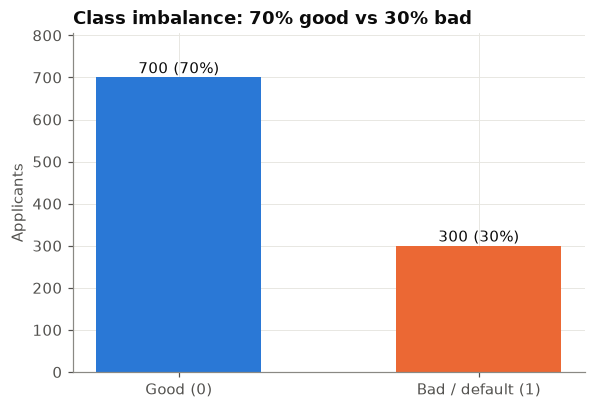

In [7]:
counts = df["default"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Good (0)", "Bad / default (1)"], counts.values, color=[PALETTE[0], PALETTE[1]], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Applicants")
ax.set_title("Class imbalance: 70% good vs 30% bad")
plt.savefig("images/class_imbalance.png")
plt.show()

**Observation:** only **300 of the 1,000 applicants (30%)** are bad risks. A model trained on this data can simply favour the majority class: predicting "good" for everyone already gives 70% accuracy and **catches zero defaulters**. That is why I rebalance the training data with **SMOTE** in section 7, and judge models by **recall** and **ROC-AUC** instead of accuracy.

### 6.2 Default rate by checking account and credit history

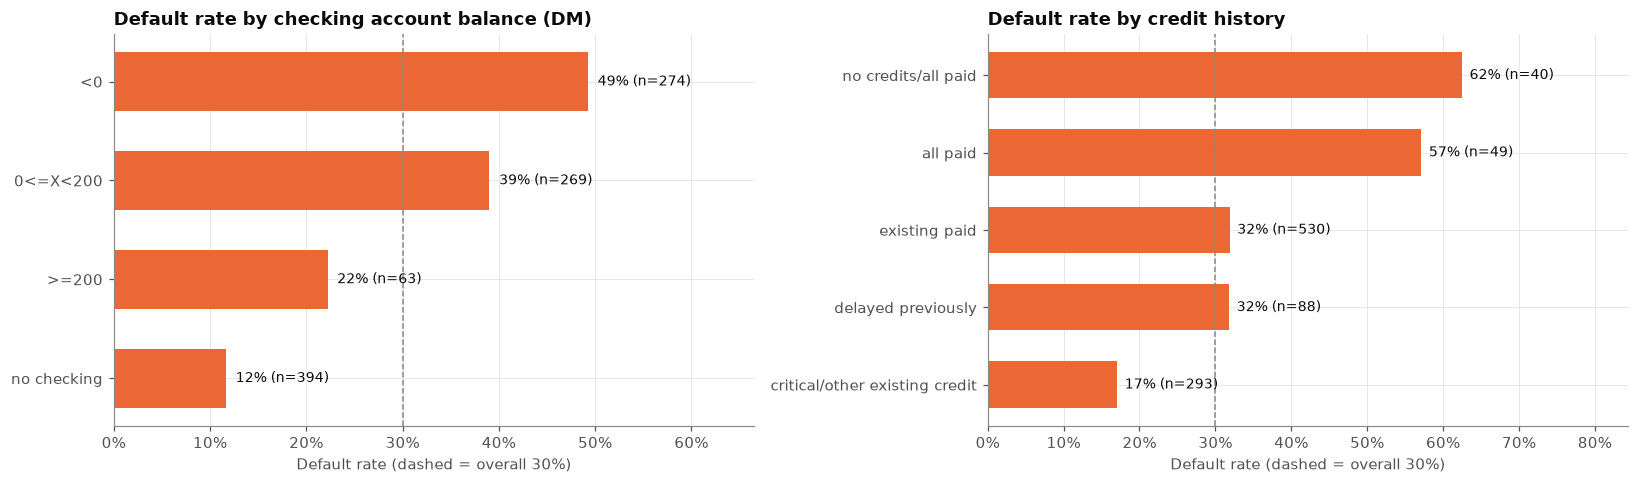

In [8]:
def default_rate_barh(col, ax, title):
    t = df.groupby(col, observed=True)["default"].agg(["mean", "size"]).sort_values("mean")
    bars = ax.barh(t.index.astype(str), t["mean"], color=PALETTE[1], height=0.6)
    for b, (rate, n) in zip(bars, t.values):
        ax.text(rate + 0.01, b.get_y() + b.get_height() / 2, f"{rate:.0%} (n={int(n)})", va="center", fontsize=9)
    ax.axvline(df["default"].mean(), color="#8a8984", ls="--", lw=1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_xlim(0, t["mean"].max() * 1.35)
    ax.set_xlabel("Default rate (dashed = overall 30%)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
default_rate_barh("checking_status", axes[0], "Default rate by checking account balance (DM)")
default_rate_barh("credit_history", axes[1], "Default rate by credit history")
plt.tight_layout()
plt.savefig("images/default_by_checking_history.png")
plt.show()

**Observation:** the **checking account balance** is the strongest single warning sign. Applicants with a **negative balance (<0 DM)** default about **49%** of the time, and those with 0-200 DM about 39%. Applicants **with no checking account** at this bank default only about **12%** of the time, probably because they bank elsewhere and are not in financial trouble. The credit history results are counter-intuitive at first sight: applicants flagged as **"critical/other existing credit"** default the *least* (about 17%), while those with **no credits or all credits paid back** default the *most* (about 60%). Experienced borrowers who already hold credits elsewhere have proven they can repay.

### 6.3 Loan duration and credit amount

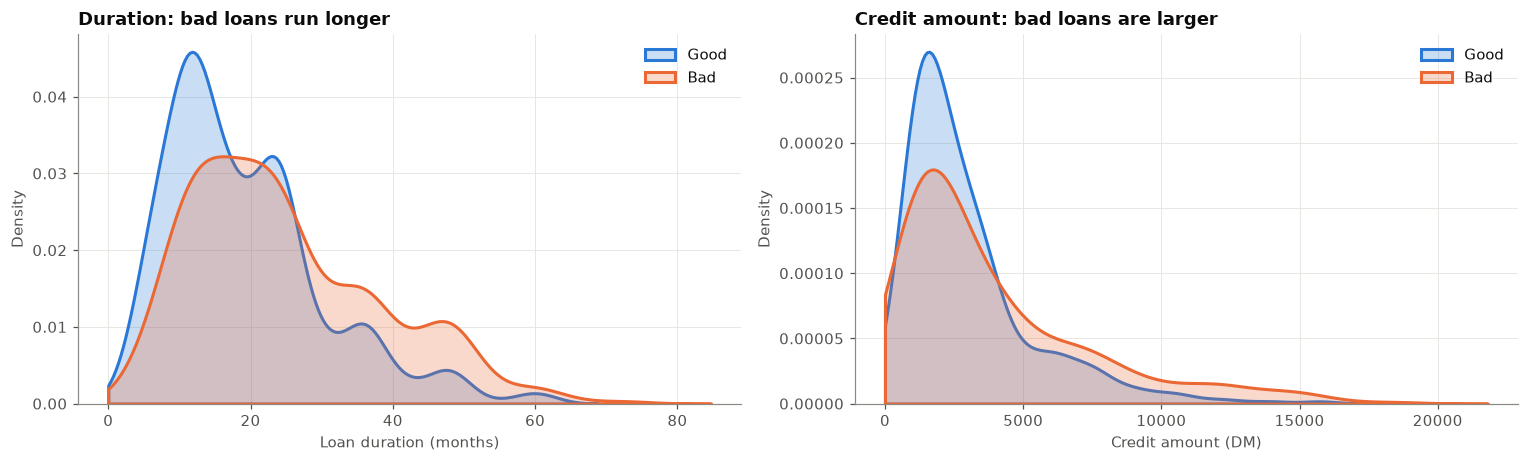

,duration,credit_amount,age
default,,,
Good,18.0,2244.0,34.0
Bad,24.0,2574.5,31.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for col, ax, xlabel in [("duration", axes[0], "Loan duration (months)"),
                        ("credit_amount", axes[1], "Credit amount (DM)")]:
    for label, color, name in [(0, PALETTE[0], "Good"), (1, PALETTE[1], "Bad")]:
        sns.kdeplot(df.loc[df["default"] == label, col], ax=ax, color=color, fill=True, alpha=0.25,
                    lw=2, label=name, clip=(0, None))
    ax.set_xlabel(xlabel)
    ax.legend()
axes[0].set_title("Duration: bad loans run longer")
axes[1].set_title("Credit amount: bad loans are larger")
plt.tight_layout()
plt.savefig("images/duration_amount.png")
plt.show()
df.groupby("default")[["duration", "credit_amount", "age"]].median().rename(index={0: "Good", 1: "Bad"})

**Observation:** bad loans are **longer** (median 24 months against 18) and **larger** (median about 2,600 DM against 2,250 DM). The density curves cross at around 24 months: above that, the share of bad loans rises clearly. Longer and bigger loans carry more risk, because there is more time for something to go wrong and more money at stake.

### 6.4 Age and loan purpose

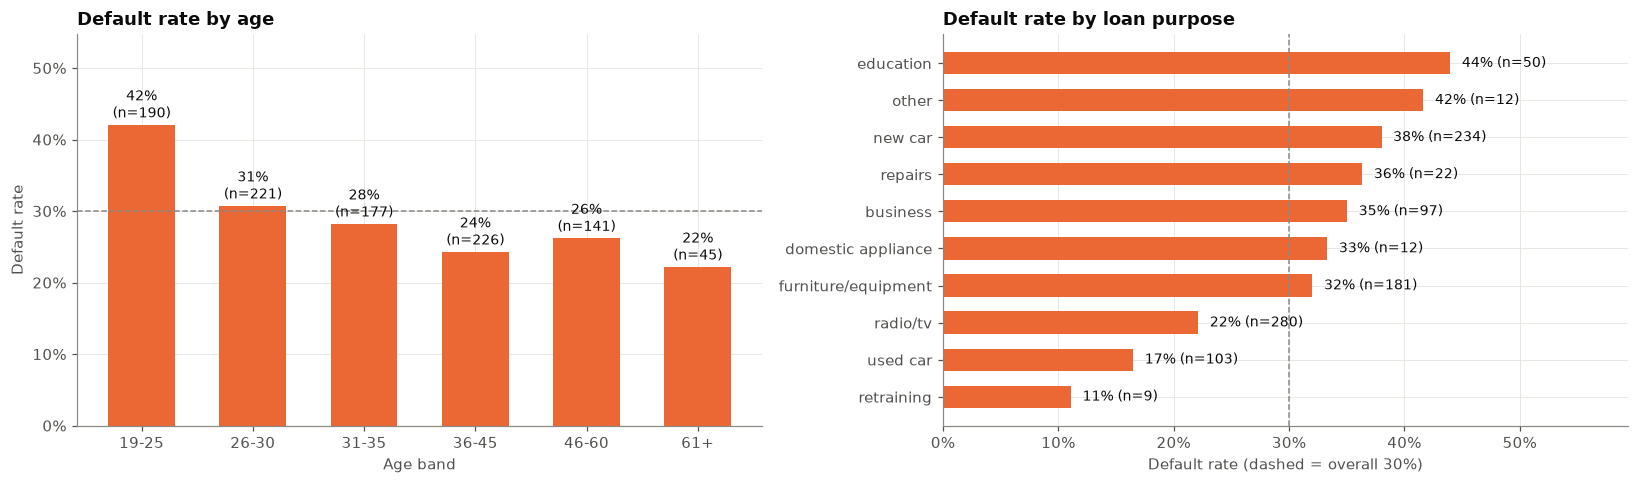

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

age_band = pd.cut(df["age"], bins=[18, 25, 30, 35, 45, 60, 80], labels=["19-25", "26-30", "31-35", "36-45", "46-60", "61+"])
rate = df.groupby(age_band, observed=True)["default"].agg(["mean", "size"])
bars = axes[0].bar(rate.index.astype(str), rate["mean"], color=PALETTE[1], width=0.6)
for b, (r, n) in zip(bars, rate.values):
    axes[0].text(b.get_x() + b.get_width() / 2, r + 0.01, f"{r:.0%}\n(n={int(n)})", ha="center", fontsize=9)
axes[0].axhline(df["default"].mean(), color="#8a8984", ls="--", lw=1)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_ylim(0, rate["mean"].max() * 1.3)
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Default rate")
axes[0].set_title("Default rate by age")

default_rate_barh("purpose", axes[1], "Default rate by loan purpose")
plt.tight_layout()
plt.savefig("images/age_purpose.png")
plt.show()

**Observation:** **younger applicants (19-25) default most** (about 42%), and the rate falls with age until the mid-40s. Among loan purposes, **education** loans and **new car** loans are the riskiest (about 38-44%), while **used car** and **radio/TV** loans are the safest (about 17-22%). Some purposes, such as *retraining* and *domestic appliance*, have very few applicants, so their rates are unreliable.

### 6.5 Correlation heatmap (numeric features)

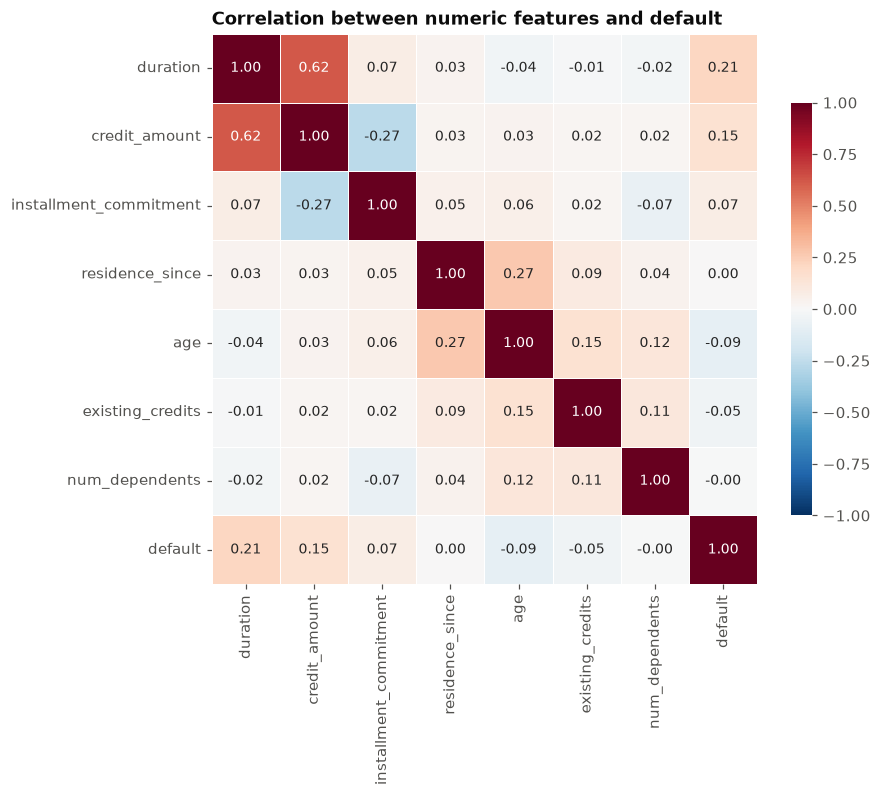

In [11]:
corr = df[num_cols + ["default"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5,
            linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"size": 9})
ax.set_title("Correlation between numeric features and default")
ax.grid(False)
plt.savefig("images/correlation_heatmap.png")
plt.show()

**Observation:** `duration` (+0.21) and `credit_amount` (+0.15) correlate most with default, and `age` is slightly negative (-0.09). The strongest correlation between features is **duration vs credit amount (0.62)**: bigger loans are repaid over longer periods. Every numeric correlation with default is weak, which tells us that most of the predictive power sits in the **categorical** features (checking account, credit history, savings).

## 7. Modeling

### 7.1 Train/test split
I keep **25% of applicants as an untouched test set** (stratified, so it also has 30% bad). All rebalancing and tuning happens on the training set only.

In [12]:
X = df.drop(columns="default")
y = df["default"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| bad rate %.2f" % y_train.mean())
print("Test: ", X_test.shape, "| bad rate %.2f" % y_test.mean())

Train: (750, 18) | bad rate 0.30
Test:  (250, 18) | bad rate 0.30


### 7.2 Preprocessing

All models share the same preprocessing, which is learned **on the training data only**:
- numeric features are **standardised**. This is needed for Logistic Regression, and also for SMOTE, which measures distances between applicants (without scaling, `credit_amount` in thousands of DM would dominate every distance).
- categorical features are **one-hot encoded**.

In [13]:
prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

### 7.3 Fixing the imbalance with SMOTE (training data only)

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new, *synthetic* bad-risk applicants. It picks a real bad applicant, finds similar bad applicants (its nearest neighbours), and generates a new applicant **at a random point in between** them.

The most important rule is that SMOTE is applied **only to the training data**. The test set keeps the real 70/30 class mix, because evaluating on synthetic applicants would give an overly optimistic score. During cross-validation I put SMOTE inside an `imblearn` **Pipeline**, so it only resamples the training folds and never the validation fold.

Here is the effect on the training set:

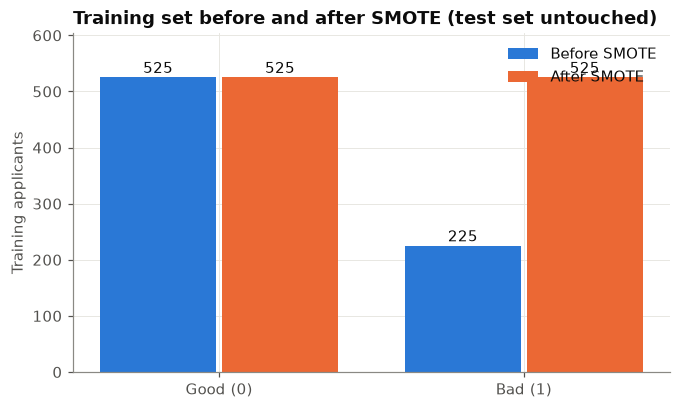

Synthetic bad applicants created: 300


In [14]:
X_train_enc = prep.fit_transform(X_train)          # fit preprocessing on training data only
X_train_res, y_train_res = SMOTE(random_state=SEED).fit_resample(X_train_enc, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_train_res).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
ax.bar(x - 0.2, before.values, width=0.38, color=PALETTE[0], label="Before SMOTE")
ax.bar(x + 0.2, after.values, width=0.38, color=PALETTE[1], label="After SMOTE")
for i in range(2):
    ax.text(i - 0.2, before.values[i] + 8, str(before.values[i]), ha="center")
    ax.text(i + 0.2, after.values[i] + 8, str(after.values[i]), ha="center")
ax.set_xticks(x, ["Good (0)", "Bad (1)"])
ax.set_ylabel("Training applicants")
ax.set_title("Training set before and after SMOTE (test set untouched)")
ax.set_ylim(0, after.max() * 1.15)
ax.legend(loc="upper right")
plt.savefig("images/smote_before_after.png")
plt.show()
print(f"Synthetic bad applicants created: {after[1] - before[1]}")

**Observation:** the training set goes from 525 good / 225 bad to **525 / 525**. SMOTE created **300 synthetic bad applicants**, and the 250 test applicants are left unchanged.

### 7.4 Which SMOTE variant? A quick experiment (cross-validation on training data)

There are two ways to use SMOTE on mixed numeric and categorical data:
1. **SMOTE after one-hot encoding** (the version shown above). It is simple, but synthetic applicants can get "in-between" values for the 0/1 category columns.
2. **SMOTENC**, a variant designed for categorical data. It interpolates the numbers and copies the most common category from the neighbours.

I compared them using **5-fold cross-validation on the training set only**, so the test set stays unseen. I also included "no resampling" as a reference. The cost is the dataset's 5:1 misclassification cost (explained in section 8).

In [15]:
def credit_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 5 * fn + fp

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"ROC-AUC": "roc_auc", "Recall": "recall", "Precision": "precision",
           "Cost": make_scorer(credit_cost, greater_is_better=False)}

experiment = []
for model_name, model in [("Logistic Regression", LogisticRegression(C=0.1, max_iter=5000)),
                          ("XGBoost", XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03,
                                                    subsample=0.8, colsample_bytree=0.7, random_state=SEED))]:
    strategies = {
        "No resampling": Pipeline([("prep", prep), ("model", model)]),
        "SMOTENC (before encoding)": Pipeline([("smote", SMOTENC(categorical_features="auto", random_state=SEED)),
                                               ("prep", prep), ("model", model)]),
        "SMOTE (after encoding)": Pipeline([("prep", prep), ("smote", SMOTE(random_state=SEED)), ("model", model)]),
    }
    for strat_name, pipe in strategies.items():
        r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        experiment.append({"Model": model_name, "Strategy": strat_name,
                           **{k: abs(r[f"test_{k}"].mean()) for k in scoring}})

pd.DataFrame(experiment).round(3)

,Model,Strategy,ROC-AUC,Recall,Precision,Cost
0,Logistic Regression,No resampling,0.770,0.387,0.626,148.4
1,Logistic Regression,SMOTENC (before encoding),0.739,0.462,0.498,142.0
2,Logistic Regression,SMOTE (after encoding),0.765,0.680,0.488,104.2
3,XGBoost,No resampling,0.776,0.476,0.633,130.8
4,XGBoost,SMOTENC (before encoding),0.760,0.542,0.561,122.0
5,XGBoost,SMOTE (after encoding),0.775,0.511,0.616,124.6


**Observation:**
- **Without resampling**, Logistic Regression catches fewer than 40% of defaulters in cross-validation.
- **SMOTE after encoding** gives the biggest improvement for Logistic Regression: recall rises from 0.39 to **0.68** and the cost falls from 148 to **104**, while ROC-AUC stays almost unchanged.
- **SMOTENC** also raises recall, but it **lowers ROC-AUC** by about 0.02-0.03. Its synthetic applicants copy the most common category of their neighbours, which seems to make them less varied than real bad applicants.
- For XGBoost the two variants end up close (cost 122-125), and both improve on no resampling.

So I use **SMOTE after encoding** for all models. This was decided from cross-validation on training data only, never from the test set.

### 7.5 Models and hyperparameter tuning

Each model is a pipeline of **preprocessing → SMOTE → classifier**, tuned with a 5-fold cross-validated grid search on **ROC-AUC**:
- **Logistic Regression**: a linear and interpretable baseline,
- **Decision Tree**: a simple, rule-like model,
- **Random Forest** and **XGBoost**: the ensemble models.

In [16]:
model_specs = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED),
                            {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [5, 10, 20, 40]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5],
                       "model__max_features": ["sqrt", 0.3]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
                {"model__n_estimators": [200, 400], "model__max_depth": [2, 3, 4],
                 "model__learning_rate": [0.03, 0.1], "model__subsample": [0.8],
                 "model__colsample_bytree": [0.7]}),
}

tuned = {}
for name, (model, grid) in model_specs.items():
    pipe = Pipeline([("prep", prep), ("smote", SMOTE(random_state=SEED)), ("model", model)])
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:<20} CV ROC-AUC = {search.best_score_:.3f} | best params: {best}")

Logistic Regression  CV ROC-AUC = 0.767 | best params: {'C': 0.03}


Decision Tree        CV ROC-AUC = 0.748 | best params: {'max_depth': 8, 'min_samples_leaf': 20}


Random Forest        CV ROC-AUC = 0.785 | best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}


XGBoost              CV ROC-AUC = 0.781 | best params: {'colsample_bytree': 0.7, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}


In cross-validation the two **ensembles score highest** (Random Forest 0.785, XGBoost 0.781), followed by Logistic Regression (0.767) and the Decision Tree (0.748). Each validation fold has only about 150 applicants, so differences of ±0.02 are within noise. The untouched test set and the business cost decide the final choice.

### 7.6 Same models without SMOTE (for comparison)

To show what SMOTE changes on the test set, I refit each model with the **same tuned hyperparameters but without SMOTE**.

In [17]:
no_smote = {}
for name, search in tuned.items():
    best_pipe = search.best_estimator_
    pipe = Pipeline([("prep", clone(best_pipe.named_steps["prep"])),
                     ("model", clone(best_pipe.named_steps["model"]))])
    no_smote[name] = pipe.fit(X_train, y_train)
print("Refitted", len(no_smote), "models without SMOTE")

Refitted 4 models without SMOTE


## 8. Evaluation on the test set

Besides the standard metrics, I report the dataset's **misclassification cost**: **5 × (missed defaulters) + 1 × (rejected good applicants)**. Lower is better.

In [18]:
def evaluate(name, smote_used, pipe):
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "SMOTE": smote_used,
            "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba), "Cost (5*FN+FP)": 5 * fn + fp}, proba

rows, probas = [], {}
for name in tuned:
    r_no, _ = evaluate(name, "No", no_smote[name])
    r_yes, p = evaluate(name, "Yes", tuned[name].best_estimator_)
    rows += [r_no, r_yes]
    probas[name] = p

results = pd.DataFrame(rows).round(3)
results.to_csv("images/results_table.csv", index=False)
results

,Model,SMOTE,Accuracy,Precision,Recall,F1,ROC-AUC,Cost (5*FN+FP)
0,Logistic Regression,No,0.764,0.722,0.347,0.468,0.808,255
1,Logistic Regression,Yes,0.740,0.548,0.760,0.637,0.809,137
2,Decision Tree,No,0.708,0.515,0.467,0.490,0.684,233
3,Decision Tree,Yes,0.664,0.452,0.560,0.500,0.705,216
4,Random Forest,No,0.740,0.632,0.320,0.425,0.795,269
5,Random Forest,Yes,0.748,0.591,0.520,0.553,0.784,207
6,XGBoost,No,0.756,0.646,0.413,0.504,0.803,237
7,XGBoost,Yes,0.744,0.580,0.533,0.556,0.794,204


**Reading the table**
- **SMOTE raises recall for every model.** Without it, the models catch only **32-47%** of defaulters. With it, they catch **52-76%**.
- The best model is **Logistic Regression with SMOTE**. It has the highest recall (**0.760**), F1 (**0.637**) and ROC-AUC (**0.809**), and by far the lowest business cost (**137**, against 204-216 for the others).
- Precision drops when SMOTE is used, because more applicants are flagged. The **cost still falls for every model**, since each missed defaulter costs 5 times more than a false alarm.
- ROC-AUC barely changes for Logistic Regression (0.808 → 0.809). SMOTE does not make it better at *ranking* applicants, but it moves the decision boundary so that many more bad applicants are caught at the default 0.5 threshold.
- The tree ensembles benefit less. Even with SMOTE they stay cautious at the 0.5 threshold (recall about 0.52-0.53), although their ranking ability (AUC 0.78-0.79) is close to Logistic Regression's.

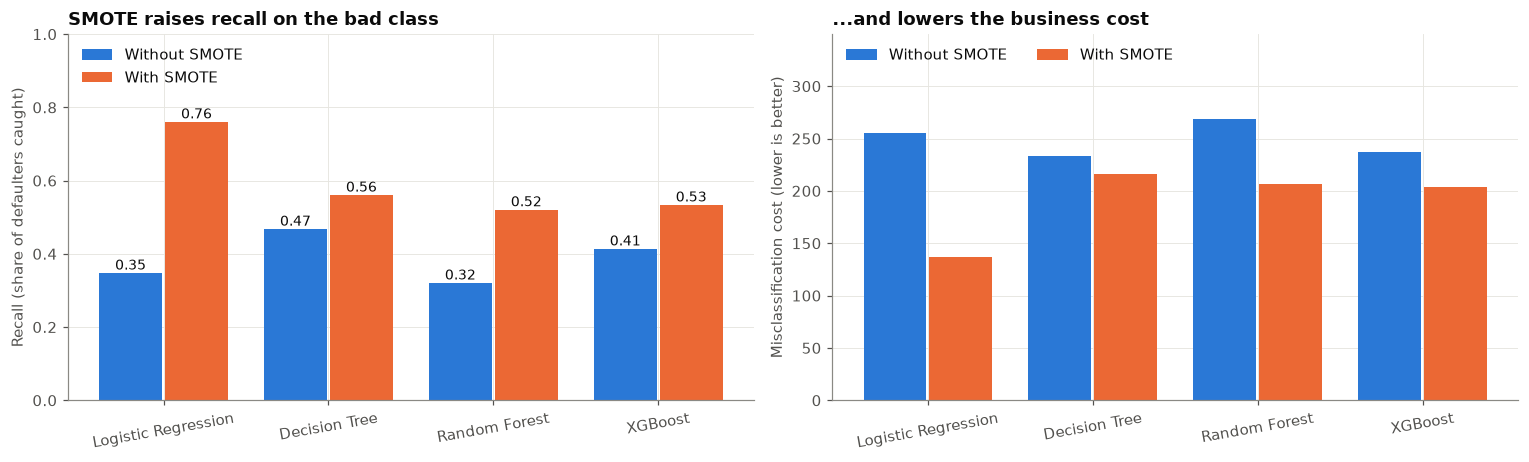

In [19]:
smote_results = results[results["SMOTE"] == "Yes"].set_index("Model")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
pivot_recall = results.pivot(index="Model", columns="SMOTE", values="Recall").loc[list(tuned)]
x = np.arange(len(pivot_recall))
axes[0].bar(x - 0.2, pivot_recall["No"], width=0.38, color=PALETTE[0], label="Without SMOTE")
axes[0].bar(x + 0.2, pivot_recall["Yes"], width=0.38, color=PALETTE[1], label="With SMOTE")
for i, (a, b) in enumerate(pivot_recall[["No", "Yes"]].values):
    axes[0].text(i - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    axes[0].text(i + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=9)
axes[0].set_xticks(x, pivot_recall.index, rotation=10)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Recall (share of defaulters caught)")
axes[0].set_title("SMOTE raises recall on the bad class")
axes[0].legend(loc="upper left")

pivot_cost = results.pivot(index="Model", columns="SMOTE", values="Cost (5*FN+FP)").loc[list(tuned)]
axes[1].bar(x - 0.2, pivot_cost["No"], width=0.38, color=PALETTE[0], label="Without SMOTE")
axes[1].bar(x + 0.2, pivot_cost["Yes"], width=0.38, color=PALETTE[1], label="With SMOTE")
axes[1].set_xticks(x, pivot_cost.index, rotation=10)
axes[1].set_ylabel("Misclassification cost (lower is better)")
axes[1].set_title("...and lowers the business cost")
axes[1].set_ylim(0, pivot_cost.values.max() * 1.3)
axes[1].legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.savefig("images/smote_effect.png")
plt.show()

**Observation:** this chart summarises the whole point of rebalancing. With SMOTE, every model catches more defaulters and the 5:1 cost goes down. The effect is largest for **Logistic Regression**: recall more than doubles (0.35 → 0.76) and the cost almost halves (255 → 137).

### 8.1 ROC curves (models trained with SMOTE)

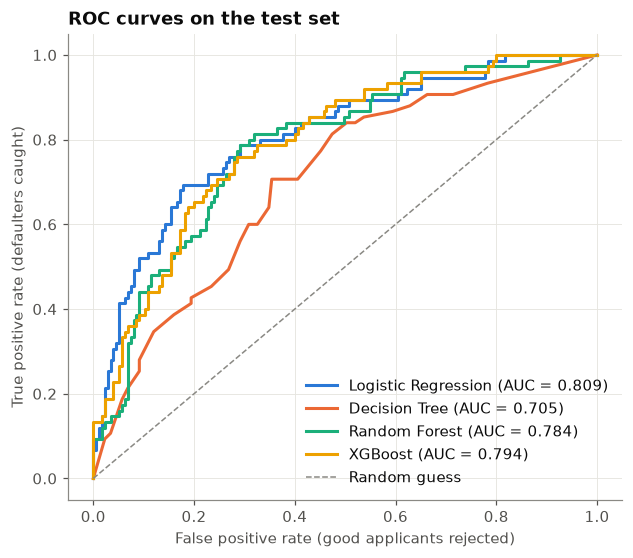

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (name, proba), color in zip(probas.items(), PALETTE):
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate (good applicants rejected)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.savefig("images/roc_curves.png")
plt.show()

**Observation:** Logistic Regression (AUC 0.809), XGBoost (0.794) and Random Forest (0.784) are close together. The single Decision Tree is clearly weaker (0.705), and its curve is step-shaped because a tree only produces a few distinct probability values. AUC values around 0.80 are typical for this dataset: 1,000 applicants and 18 features only reveal part of a person's credit risk.

### 8.2 Confusion matrices (models trained with SMOTE)

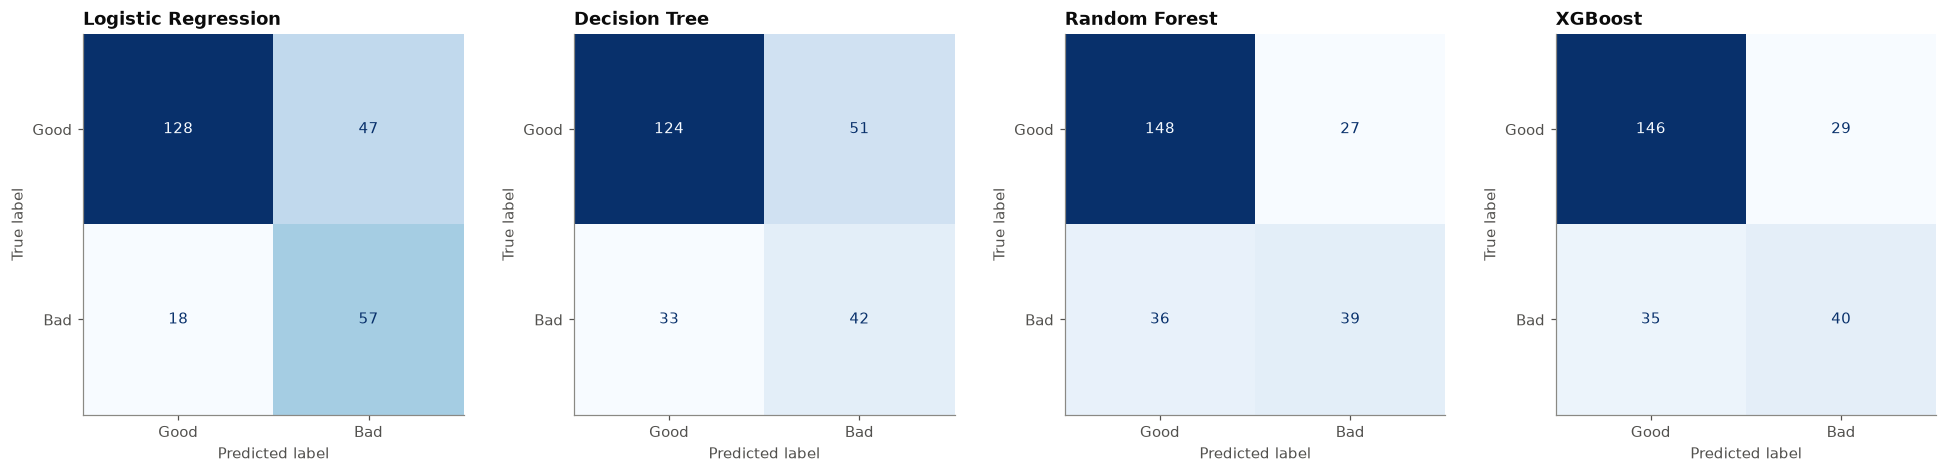

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, proba) in zip(axes, probas.items()):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Good", "Bad"]).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                    values_format="d")
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png")
plt.show()

**Observation:** the test set has **75 defaulters**. Logistic Regression catches **57** of them and misses only 18 (bottom row). The tree models catch about 39-42. Logistic Regression pays for this with 47 false alarms (top-right): good applicants who would be sent for a manual review. Under the 5:1 cost matrix that is clearly worth it (cost = 5 × 18 + 47 = 137).

## 9. Explaining the model with SHAP

**SHAP (SHapley Additive exPlanations)** splits each prediction into contributions from the individual features. A positive SHAP value pushes the applicant **towards default**, and a negative value pushes towards *good*. Values are in **log-odds** of default.

I explain the **best model, Logistic Regression with SMOTE**, using SHAP's `LinearExplainer`. The **real (non-SMOTE) training applicants** serve as the background distribution. At the end I check whether the XGBoost ensemble relies on the same features.

In [22]:
best_pipe = tuned["Logistic Regression"].best_estimator_
prep_fitted = best_pipe.named_steps["prep"]
lr_model = best_pipe.named_steps["model"]

X_train_t = prep_fitted.transform(X_train)
X_test_t = prep_fitted.transform(X_test)
feature_names = [n.replace("num__", "").replace("cat__", "") for n in prep_fitted.get_feature_names_out()]

explainer = shap.LinearExplainer(lr_model, shap.maskers.Independent(X_train_t, max_samples=len(X_train_t)))
raw = explainer(X_test_t)

# For readable plots, show numeric features in their original units (months, DM, years)
X_display = X_test_t.copy()
X_display[:, :len(num_cols)] = prep_fitted.named_transformers_["num"].inverse_transform(X_test_t[:, :len(num_cols)])
shap_values = shap.Explanation(values=raw.values, base_values=raw.base_values,
                               data=X_display, feature_names=feature_names)
print("SHAP values:", shap_values.values.shape)

SHAP values: (250, 55)


### 9.1 SHAP summary plot (beeswarm)

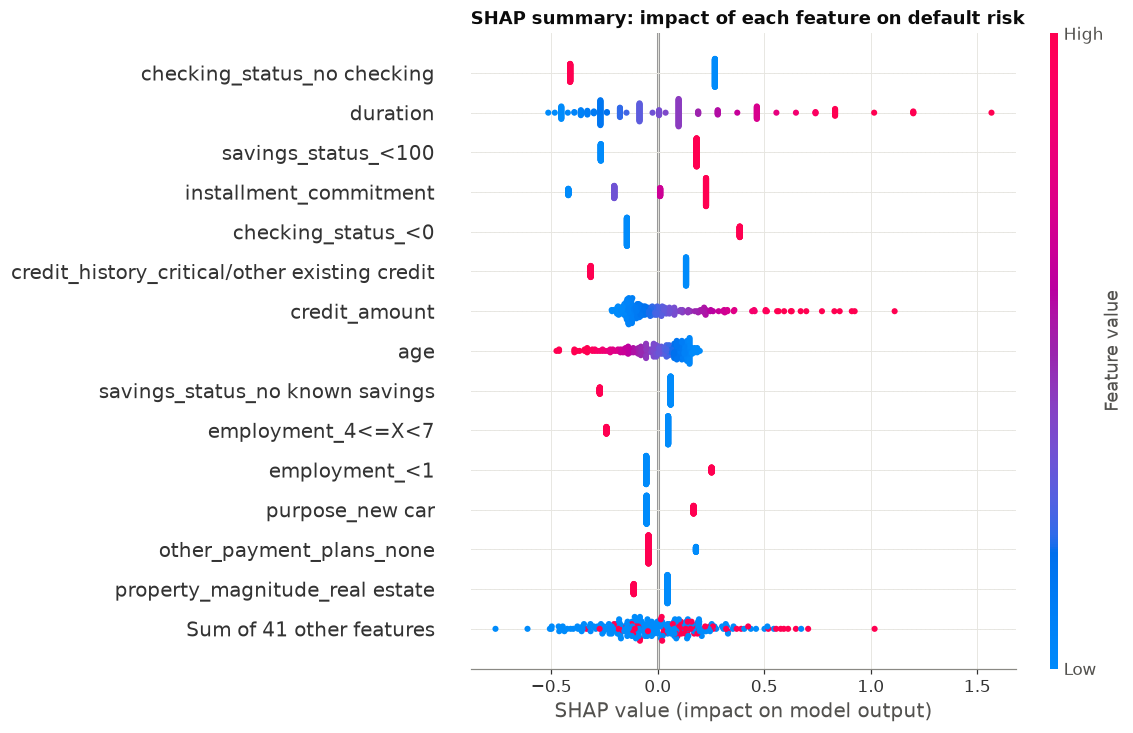

In [23]:
plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP summary: impact of each feature on default risk", loc="left", fontweight="bold")
plt.savefig("images/shap_summary.png")
plt.show()

**How to read it:** each dot is one test applicant. Its position shows how much that feature pushed the prediction towards default (right) or towards good (left), and its colour shows the feature value (red = high, blue = low; for one-hot features, red = "yes").

**Observation:**
- **`checking_status_no checking` is the most important feature.** Applicants with no checking account at the bank (red) are pushed clearly towards *good*.
- **Long `duration`** (red, right side) is the strongest risk factor and can add more than 1 log-odds for very long loans. Short loans (blue) reduce risk.
- **Savings below 100 DM**, a **high instalment rate** (`installment_commitment`) and an **overdrawn checking account (<0)** all raise risk.
- A **"critical/other existing credit"** history, **older age** and **known savings** lower risk. Large **credit amounts** raise it.
- Because the model is linear, each yes/no feature has only two SHAP values (two clusters of dots), while numeric features spread out smoothly.

### 9.2 Global feature importance (mean |SHAP|)

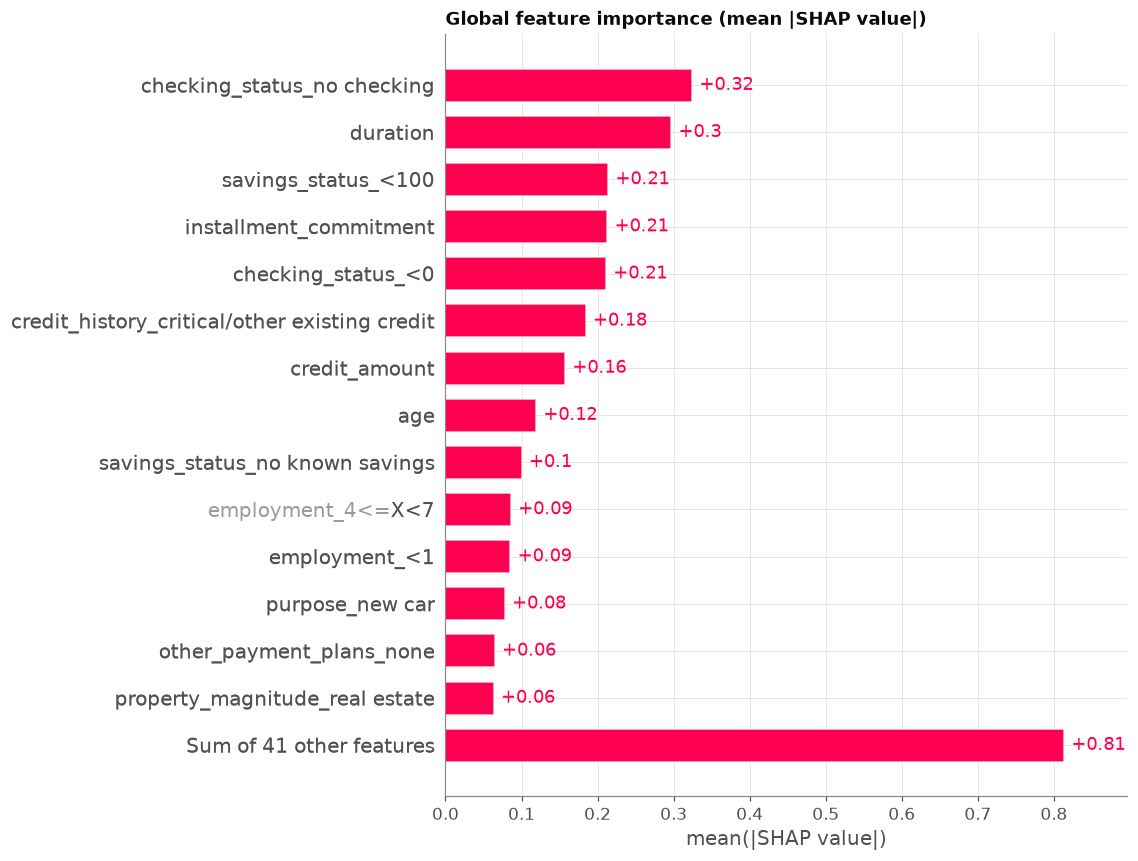

In [24]:
plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Global feature importance (mean |SHAP value|)", loc="left", fontweight="bold")
plt.savefig("images/shap_importance.png")
plt.show()

**Observation:** the top drivers are **checking account status** (no account or an overdrawn one), **loan duration**, **low savings**, **instalment burden**, **credit history**, **credit amount** and **age**. They match the EDA findings and common credit-risk sense, which is a good sign that the model has learned real patterns rather than noise.

### 9.3 Explaining one individual applicant

A credit officer must be able to explain **why a specific applicant was flagged**. Under the EU GDPR, applicants have a right to meaningful information about automated decisions. I pick the test applicant with the **highest predicted default risk** who really did default, and break down that prediction.

In [25]:
test_proba = best_pipe.predict_proba(X_test)[:, 1]
defaulters = np.where(y_test.values == 1)[0]
idx = defaulters[np.argmax(test_proba[defaulters])]

print(f"Applicant (test row {idx}) - predicted probability of default: {test_proba[idx]:.1%} | actual: bad")
X_test.iloc[idx].to_frame("value")

Applicant (test row 111) - predicted probability of default: 92.3% | actual: bad


,value
checking_status,0<=X<200
duration,60
credit_history,existing paid
purpose,new car
credit_amount,7408
savings_status,100<=X<500
employment,<1
installment_commitment,4
other_parties,none
residence_since,2


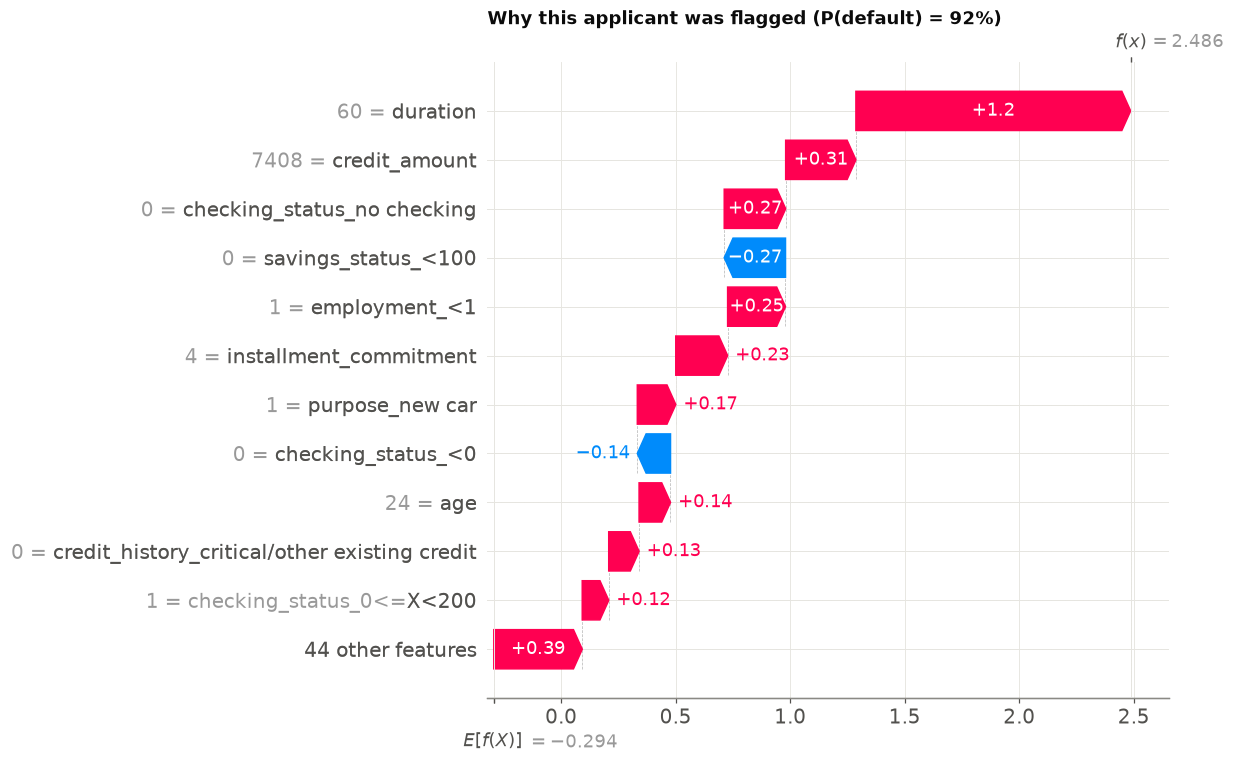

In [26]:
plt.figure()
shap.plots.waterfall(shap_values[idx], max_display=12, show=False)
plt.title(f"Why this applicant was flagged (P(default) = {test_proba[idx]:.0%})", loc="left", fontweight="bold")
plt.savefig("images/shap_waterfall_applicant.png")
plt.show()

**How to read the waterfall:** the plot starts at the model's average output, E[f(x)] at the bottom. Each bar adds the effect of one feature: red bars increase the default risk and blue bars decrease it. The sum ends at this applicant's score f(x) at the top, in log-odds.

**Observation for this applicant:** a **24-year-old** asking for **7,408 DM over 60 months** to buy a new car, employed for **less than a year**, with the highest instalment rate (4). The model estimates a **92% probability of default** (and the applicant really did default).
- The **60-month duration alone adds +1.2 log-odds**. It is by far the biggest risk factor.
- Further risk comes from the **large amount** (+0.31), not having the low-risk "no checking account" profile (+0.27), **short employment** (+0.25), the **high instalment burden** (+0.23), the **new-car purpose** (+0.17) and **young age** (+0.14).
- Only two features reduce the risk: savings are not in the lowest band (-0.27), and the checking account is not overdrawn (-0.14).

A loan officer could use this to explain the decision, and to suggest what would change it. A **much shorter loan or a smaller amount** would remove the largest risk contributions.

### 9.4 Does the XGBoost ensemble rely on the same features?

As a sanity check, I compute SHAP values for the tuned XGBoost model (`TreeExplainer`) and compare its top features with those of Logistic Regression.

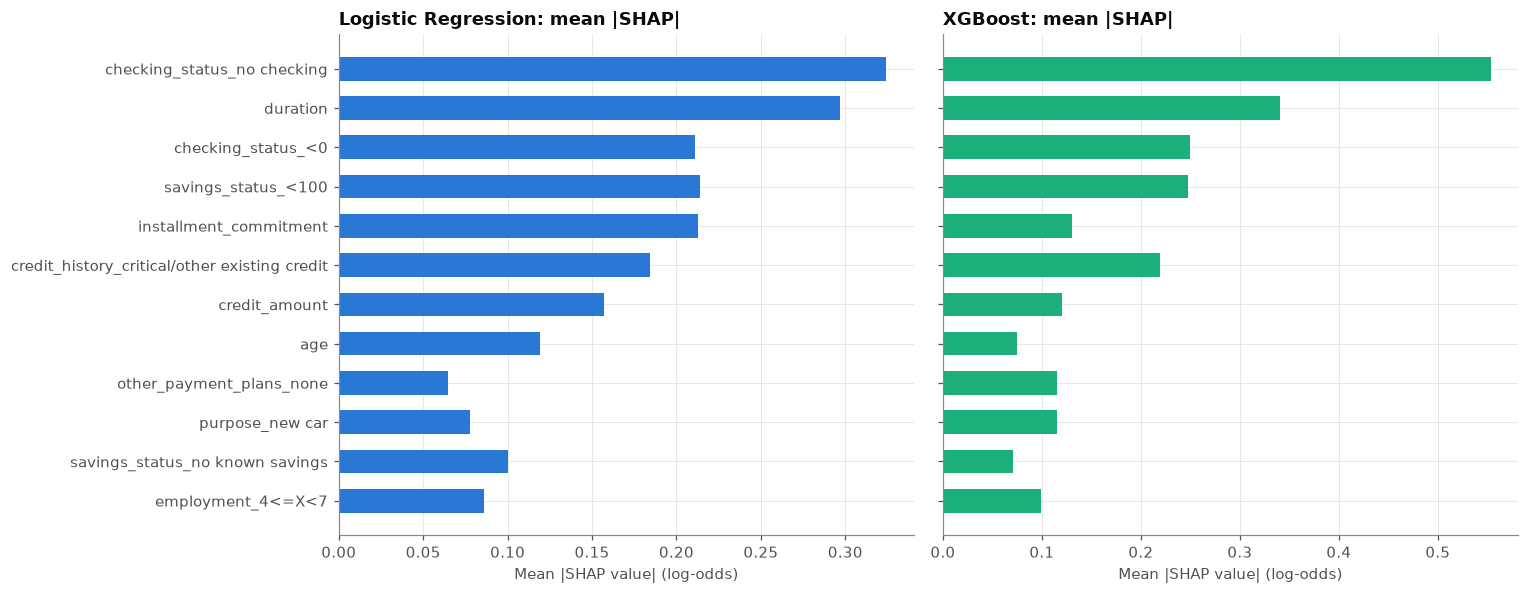

Rank correlation of feature importance (Spearman): 0.83


In [27]:
xgb_pipe = tuned["XGBoost"].best_estimator_
xgb_shap = shap.TreeExplainer(xgb_pipe.named_steps["model"])(xgb_pipe.named_steps["prep"].transform(X_test))

imp = pd.DataFrame({"Logistic Regression": np.abs(shap_values.values).mean(axis=0),
                    "XGBoost": np.abs(xgb_shap.values).mean(axis=0)}, index=feature_names)
top = imp.rank(ascending=False).min(axis=1).sort_values().index[:12]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, col, color in zip(axes, imp.columns, [PALETTE[0], PALETTE[2]]):
    ax.barh(top[::-1], imp.loc[top[::-1], col], color=color, height=0.6)
    ax.set_title(f"{col}: mean |SHAP|")
    ax.set_xlabel("Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.savefig("images/shap_lr_vs_xgb.png")
plt.show()
print("Rank correlation of feature importance (Spearman): %.2f"
      % imp.loc[top].corr(method="spearman").iloc[0, 1])

**Observation:** two very different models, one linear and one a boosted tree ensemble, rank the features very similarly (Spearman rank correlation **0.83** on the top 12). Both put **"no checking account"** and **duration** at the top. XGBoost leans even more on the checking account status and credit history, and less on instalment rate and age. This agreement is strong evidence that these are genuine risk drivers and not artefacts of one model.

## 10. Insights and conclusion

**Best model: Logistic Regression + SMOTE**, with test **recall 0.76**, **ROC-AUC 0.809**, F1 0.637 and the **lowest misclassification cost (137)**. It catches **57 of the 75 defaulters** in the test set. It is also the easiest model to explain to regulators and customers.

**What I learned about the imbalance**
- **SMOTE was essential.** For Logistic Regression it more than doubled recall (0.35 → 0.76) and almost halved the business cost (255 → 137), with no loss in ROC-AUC.
- SMOTE was applied **only to the training data**, and only to the training folds during cross-validation, so the test results are honest.
- **SMOTE after one-hot encoding** beat **SMOTENC** in cross-validation on the training data. SMOTENC lowered ROC-AUC by about 0.02-0.03.
- The **tree ensembles** had the best cross-validated AUC, but stayed conservative at the 0.5 threshold even after SMOTE. They would need threshold tuning to reach a similar recall.

**What drives credit risk (EDA + SHAP)**
1. **Checking account status.** Overdrawn accounts are the biggest red flag (49% default rate), and "no checking account" is the safest group (12%).
2. **Loan duration and amount.** Loans over 24 months default 44% of the time, against 26% for shorter ones.
3. **Savings and instalment burden.** Low savings and high instalments relative to income raise risk.
4. **Credit history and age.** A proven repayment history and older age lower risk, and applicants aged 19-25 default 42% of the time.

**Recommendations for the bank**
- Use the model as a **screening tool**: fast-track low-risk applicants and send high-risk ones to **manual review**, rather than rejecting them automatically.
- Use the SHAP explanation of each flagged applicant to offer **safer alternatives**, such as a shorter duration, a smaller amount, a guarantor, or building up savings first.
- **Monitor fairness.** I removed sex and nationality, but other features (age, housing, job) can still act as proxies. Approval rates should be checked across groups before deployment.

**Limitations.** The data is from the 1990s, comes from one German bank, and contains only 1,000 applicants (75 defaulters in the test set), so the metrics have wide uncertainty. A real system would need recent data, credit bureau scores, probability calibration (SMOTE distorts predicted probabilities), and a decision threshold chosen from actual loss figures.